# Deep Learning, Phase 2 (CNNs), Day 1: Images, Convolution, Padding, Stride and Pooling
Today we build the core operation of a CNN **by hand** in NumPy, so that `nn.Conv2d` is not a black box tomorrow.
1. Images as numbers  2. Convolution by hand  3. Filters and feature maps  4. Padding, stride and output size  5. ReLU and max pooling  6. Why CNNs need fewer parameters  7. Filters are learnable


In [ ]:
import numpy as np
import matplotlib.pyplot as plt, seaborn as sns
from scipy.signal import correlate2d
from sklearn.datasets import load_sample_image, load_digits
sns.set_theme(style='white')
plt.rcParams['image.cmap'] = 'gray'

## 1. An image is a grid of numbers
- A **grayscale** image has shape (height, width), each pixel is a number (0 = black, 255 = white).
- A **colour** image has 3 **channels** (red, green, blue): shape (height, width, 3) in NumPy, or (3, height, width) in PyTorch.

Colour image shape (H, W, channels): (427, 640, 3) | dtype: uint8 | values from 0 to 255
Grayscale image shape: (214, 320)


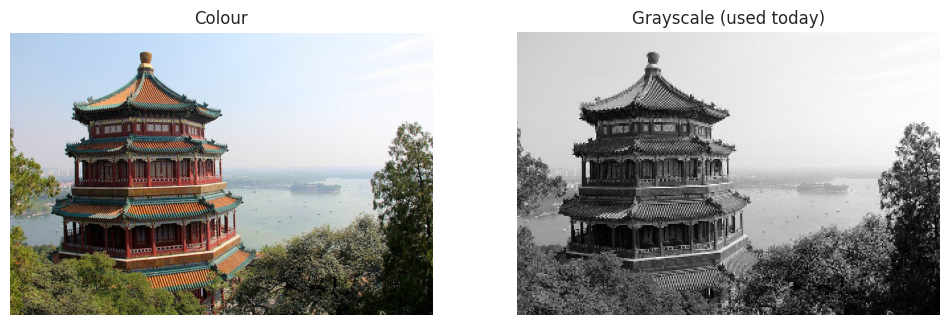

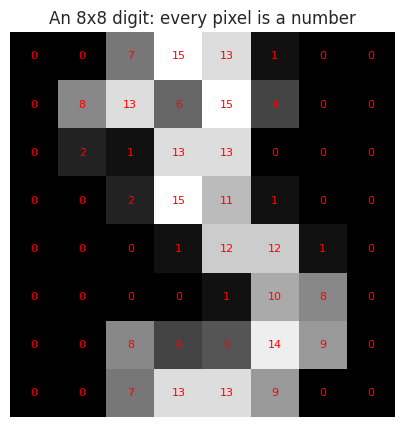

In [ ]:
img_rgb = load_sample_image('china.jpg')          # a photo that ships with scikit-learn
print('Colour image shape (H, W, channels):', img_rgb.shape, '| dtype:', img_rgb.dtype, '| values from', img_rgb.min(), 'to', img_rgb.max())
gray = img_rgb.mean(axis=2) / 255.0               # average the channels, scale to 0..1
gray = gray[::2, ::2]                              # keep every 2nd pixel, to make it smaller and faster
print('Grayscale image shape:', gray.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 4)); ax[0].imshow(img_rgb); ax[0].set_title('Colour'); ax[1].imshow(gray); ax[1].set_title('Grayscale (used today)')
for a in ax: a.axis('off')
plt.show()

digit = load_digits().images[3]                    # a tiny 8x8 handwritten digit
plt.figure(figsize=(5, 5)); plt.imshow(digit); plt.title('An 8x8 digit: every pixel is a number')
for (i, j), v in np.ndenumerate(digit): plt.text(j, i, int(v), ha='center', va='center', color='red', fontsize=8)
plt.axis('off'); plt.show()

## 2. Convolution by hand
A **filter (kernel)** is a small grid of weights, for example 3x3. We slide it over the image. At each position we **multiply the kernel with the pixels under it and add everything up**. That single number becomes one pixel of the output, the **feature map**.

(Deep learning libraries actually compute cross-correlation, i.e. without flipping the kernel, and call it convolution. We do the same.)

First one position, step by step:

In [ ]:
image = np.array([[1, 2, 0, 1, 3],
                  [0, 1, 3, 1, 0],
                  [2, 1, 0, 0, 1],
                  [1, 0, 1, 2, 2],
                  [0, 3, 1, 0, 1]], dtype=float)
kernel = np.array([[1, 0, -1],
                   [1, 0, -1],
                   [1, 0, -1]], dtype=float)         # a vertical-edge filter

patch = image[0:3, 0:3]                                # the 3x3 patch at the top-left corner
print('Patch:\n', patch); print('Kernel:\n', kernel)
print('Element-wise product:\n', patch * kernel)
print('Sum = first output pixel =', (patch * kernel).sum())

Patch:
 [[1. 2. 0.]
 [0. 1. 3.]
 [2. 1. 0.]]
Kernel:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]
Element-wise product:
 [[ 1.  0. -0.]
 [ 0.  0. -3.]
 [ 2.  0. -0.]]
Sum = first output pixel = 0.0


In [ ]:
def conv2d(image, kernel, stride=1, padding=0):
    if padding > 0: image = np.pad(image, padding)              # add a border of zeros
    kh, kw = kernel.shape
    out_h = (image.shape[0] - kh) // stride + 1
    out_w = (image.shape[1] - kw) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            patch = image[i * stride: i * stride + kh, j * stride: j * stride + kw]
            out[i, j] = (patch * kernel).sum()
    return out

out = conv2d(image, kernel)
print(out)
print('Matches SciPy?', np.allclose(out, correlate2d(image, kernel, mode='valid')))

[[ 0.  2. -1.]
 [-1. -1.  1.]
 [ 1.  2. -2.]]
Matches SciPy? True


The 5x5 image gave a 3x3 output: the kernel only fits in 3 x 3 positions. Next: filters on a real photo.

## 3. Filters detect patterns
Different kernels respond to different patterns. The output is large where the pattern is present.

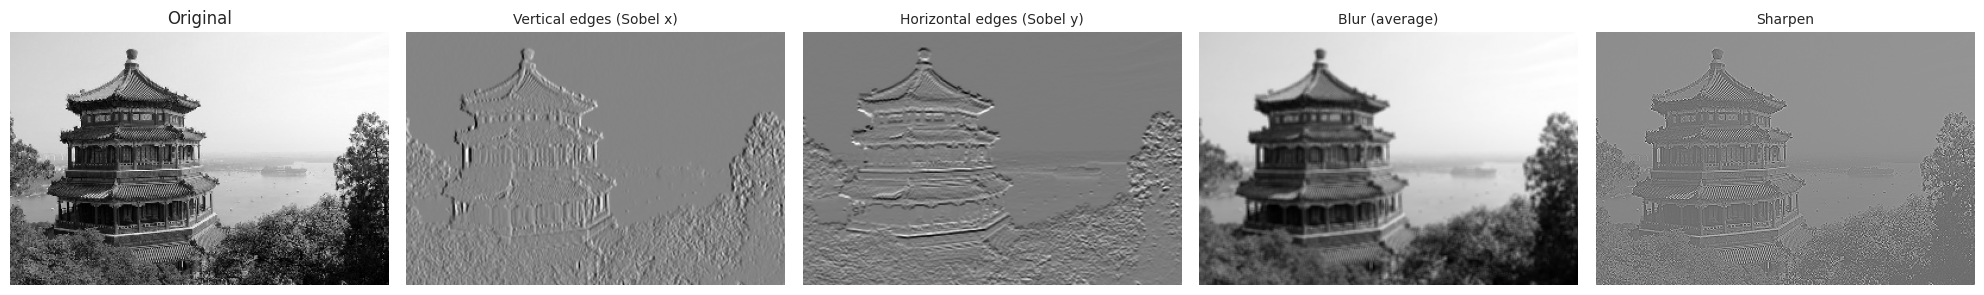

In [ ]:
filters = {
    'Vertical edges (Sobel x)':   np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float),
    'Horizontal edges (Sobel y)': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], float),
    'Blur (average)':             np.ones((3, 3)) / 9,
    'Sharpen':                    np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], float),
}
fig, ax = plt.subplots(1, 5, figsize=(20, 3.6)); ax[0].imshow(gray); ax[0].set_title('Original')
for a, (name, k) in zip(ax[1:], filters.items()):
    a.imshow(conv2d(gray, k)); a.set_title(name, fontsize=10)
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

## 4. Padding, stride and the output size
- **Padding** `p`: add a border of zeros, so the output does not shrink (and edge pixels are used more).
- **Stride** `s`: how many pixels the filter moves each step. A stride of 2 halves the output size.

**Output size = floor((n + 2p - f) / s) + 1**, where `n` is the input size and `f` the filter size.

In [ ]:
def out_size(n, f, p=0, s=1): return (n + 2 * p - f) // s + 1

rows = []
test = np.random.rand(28, 28)
for f, p, s in [(3, 0, 1), (3, 1, 1), (5, 0, 1), (5, 2, 1), (3, 0, 2), (3, 1, 2)]:
    real = conv2d(test, np.ones((f, f)), stride=s, padding=p).shape
    rows.append((f, p, s, out_size(28, f, p, s), real))
import pandas as pd
pd.DataFrame(rows, columns=['filter f', 'padding p', 'stride s', 'formula (28x28 input)', 'real output shape'])

,filter f,padding p,stride s,formula (28x28 input),real output shape
0,3,0,1,26,"(26, 26)"
1,3,1,1,28,"(28, 28)"
2,5,0,1,24,"(24, 24)"
3,5,2,1,28,"(28, 28)"
4,3,0,2,13,"(13, 13)"
5,3,1,2,14,"(14, 14)"


**Rule of thumb:** a 3x3 filter with padding 1 and stride 1 keeps the size ("same" padding). Check the table: row 2 gives 28.

## 5. ReLU and max pooling
After the convolution a CNN applies **ReLU** (as in Phase 1). Then **max pooling** shrinks the map: it slides a 2x2 window with stride 2 and keeps the **maximum** of each window. Result: half the height and width, fewer values for the next layer, and the features become slightly insensitive to small shifts.

Feature map: (212, 318) -> after 2x2 max pooling: (106, 159)


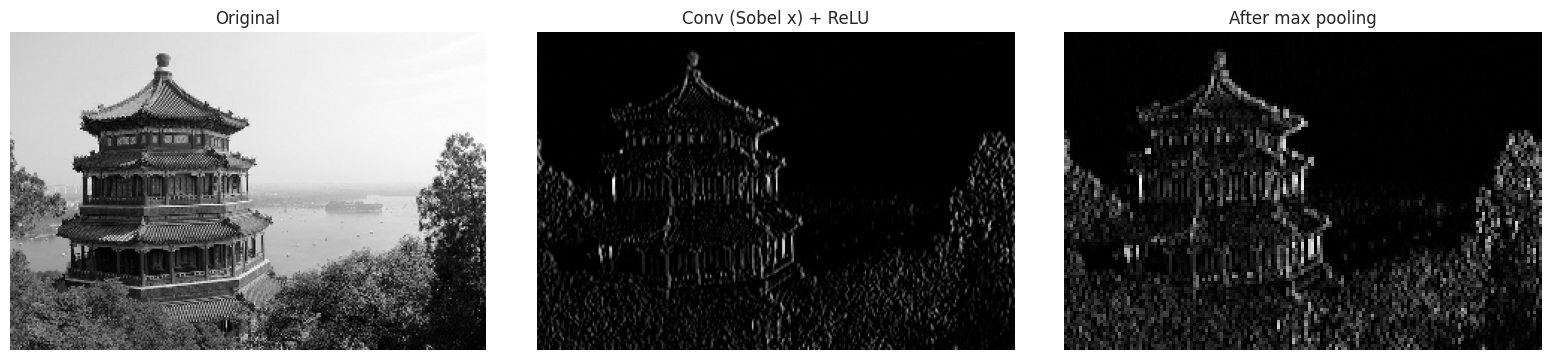

Correlation between the maps of the original and the 1-pixel-shifted image: before pooling 0.345, after pooling 0.649


In [ ]:
def max_pool(x, size=2, stride=2):
    out_h, out_w = (x.shape[0] - size) // stride + 1, (x.shape[1] - size) // stride + 1
    out = np.zeros((out_h, out_w))
    for i in range(out_h):
        for j in range(out_w):
            out[i, j] = x[i * stride: i * stride + size, j * stride: j * stride + size].max()
    return out

fmap = np.maximum(0, conv2d(gray, filters['Vertical edges (Sobel x)']))     # convolution + ReLU
pooled = max_pool(fmap)
print('Feature map:', fmap.shape, '-> after 2x2 max pooling:', pooled.shape)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.6)); ax[0].imshow(gray); ax[0].set_title('Original'); ax[1].imshow(fmap); ax[1].set_title('Conv (Sobel x) + ReLU'); ax[2].imshow(pooled); ax[2].set_title('After max pooling')
for a in ax: a.axis('off')
plt.tight_layout(); plt.show()

# Small shifts: pooling makes the result similar
shifted = np.roll(gray, 1, axis=1)
f2 = max_pool(np.maximum(0, conv2d(shifted, filters['Vertical edges (Sobel x)'])))
a, b = fmap.ravel()[:fmap.size], np.maximum(0, conv2d(shifted, filters['Vertical edges (Sobel x)'])).ravel()
print('Correlation between the maps of the original and the 1-pixel-shifted image: before pooling %.3f, after pooling %.3f' % (np.corrcoef(a, b)[0, 1], np.corrcoef(pooled.ravel(), f2.ravel())[0, 1]))

## 6. Why CNNs use far fewer parameters than an MLP
A convolution layer **shares** the same small filter across the whole image, and each output only looks at a **local** patch. Compare, for a 28x28 grayscale image and 16 output feature maps:

In [ ]:
n_in = 28 * 28
conv_params = 16 * (3 * 3 * 1) + 16                       # 16 filters of 3x3x1, plus 16 biases
out_side = out_size(28, 3, 1, 1)                           # padding 1 keeps 28x28
fc_params = n_in * (16 * out_side * out_side) + 16 * out_side * out_side    # a dense layer producing the same number of outputs
print(f'Conv layer (16 filters 3x3): {conv_params:,} parameters')
print(f'Fully connected layer giving the same {16 * out_side * out_side:,} outputs: {fc_params:,} parameters')
print(f'Ratio: {fc_params / conv_params:,.0f}x more')

Conv layer (16 filters 3x3): 160 parameters
Fully connected layer giving the same 12,544 outputs: 9,847,040 parameters
Ratio: 61,544x more


## 7. Filters are learnable weights
We used hand-made filters, but in a CNN the filter values are **weights learned by gradient descent**, exactly like the weights in Phase 1. Demonstration with PyTorch: start with a **random** 3x3 filter and train it to reproduce the vertical-edge (Sobel x) output.

In [ ]:
import torch, torch.nn.functional as F
torch.manual_seed(0)
x = torch.tensor(gray, dtype=torch.float32)[None, None]                    # shape (batch=1, channels=1, H, W)
sobel = torch.tensor(filters['Vertical edges (Sobel x)'], dtype=torch.float32)[None, None]
target = F.conv2d(x, sobel)                                                # what we want the filter to output

w = torch.randn(1, 1, 3, 3, requires_grad=True)                            # random starting filter
opt = torch.optim.Adam([w], lr=0.2); losses = []
for step in range(600):
    opt.zero_grad(); loss = F.mse_loss(F.conv2d(x, w), target); loss.backward(); opt.step(); losses.append(loss.item())
print('Loss: start %.4f -> end %.8f' % (losses[0], losses[-1]))
print('Learned filter:\n', w.detach().numpy()[0, 0].round(2)); print('Sobel x filter:\n', sobel.numpy()[0, 0])

Loss: start 2.8478 -> end 0.00000000
Learned filter:
 [[-1. -0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]
Sobel x filter:
 [[-1.  0.  1.]
 [-2.  0.  2.]
 [-1.  0.  1.]]


The network found the Sobel filter by itself, just by reducing the error. A real CNN does the same for hundreds of filters at once, but with the classification loss instead of a target image, so it learns whichever filters help to recognise the classes.